# My Energy Consumption Project

In [1]:
x = 5 * 2
print(x)

10


In [2]:
print("kWh is energy")

kWh is energy


In [3]:
import pandas as pd
print(pd.__version__)

3.0.6


In [4]:
import matplotlib.pyplot as plt
print("matplotlib loaded")

matplotlib loaded


In [5]:
df = pd.read_csv("household_power_consumption.txt", sep=";")

C:\Users\HP\AppData\Local\Temp\ipykernel_32704\2456779612.py:1: DtypeWarning: Columns (2: Global_active_power, 3: Global_reactive_power, 4: Voltage, 5: Global_intensity, 6: Sub_metering_1, 7: Sub_metering_2) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("household_power_consumption.txt", sep=";")


In [6]:
df.head()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.840,18.400,0.000,1.000,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.630,23.000,0.000,1.000,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.290,23.000,0.000,2.000,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.740,23.000,0.000,1.000,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.680,15.800,0.000,1.000,17.0


In [7]:
df.shape

(2075259, 9)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   str    
 1   Time                   str    
 2   Global_active_power    object 
 3   Global_reactive_power  object 
 4   Voltage                object 
 5   Global_intensity       object 
 6   Sub_metering_1         object 
 7   Sub_metering_2         object 
 8   Sub_metering_3         float64
dtypes: float64(1), object(6), str(2)
memory usage: 142.5+ MB


In [9]:
df.isin(["?"]).sum()

Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3               0
dtype: int64

In [10]:
df.isnull().sum()

Date                         0
Time                         0
Global_active_power          0
Global_reactive_power        0
Voltage                      0
Global_intensity             0
Sub_metering_1               0
Sub_metering_2               0
Sub_metering_3           25979
dtype: int64

In [11]:
df.replace("?", pd.NA, inplace=True)

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.840,18.400,0.000,1.000,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.630,23.000,0.000,1.000,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.290,23.000,0.000,2.000,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.740,23.000,0.000,1.000,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.680,15.800,0.000,1.000,17.0
...,...,...,...,...,...,...,...,...,...
2075254,26/11/2010,20:58:00,0.946,0.0,240.43,4.0,0.0,0.0,0.0
2075255,26/11/2010,20:59:00,0.944,0.0,240.0,4.0,0.0,0.0,0.0
2075256,26/11/2010,21:00:00,0.938,0.0,239.82,3.8,0.0,0.0,0.0
2075257,26/11/2010,21:01:00,0.934,0.0,239.7,3.8,0.0,0.0,0.0


In [12]:
df.isnull().sum()

Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64

In [13]:
missing_percentage = (df.isnull().sum() / len(df)) * 100
missing_percentage

Date                     0.000000
Time                     0.000000
Global_active_power      1.251844
Global_reactive_power    1.251844
Voltage                  1.251844
Global_intensity         1.251844
Sub_metering_1           1.251844
Sub_metering_2           1.251844
Sub_metering_3           1.251844
dtype: float64

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df.dtypes

Date                         str
Time                         str
Global_active_power       object
Global_reactive_power     object
Voltage                   object
Global_intensity          object
Sub_metering_1            object
Sub_metering_2            object
Sub_metering_3           float64
dtype: object

In [16]:
df.columns

Index(['Date', 'Time', 'Global_active_power', 'Global_reactive_power',
       'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2',
       'Sub_metering_3'],
      dtype='str')

In [17]:
numeric_columns = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

df[numeric_columns] = df[numeric_columns].apply(pd.to_numeric, errors="coerce")

In [18]:
df.dtypes

Date                         str
Time                         str
Global_active_power      float64
Global_reactive_power    float64
Voltage                  float64
Global_intensity         float64
Sub_metering_1           float64
Sub_metering_2           float64
Sub_metering_3           float64
dtype: object

In [19]:
df["datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H:%M:%S"
)

In [20]:
df[["Date", "Time", "datetime"]].head()

,Date,Time,datetime
0,16/12/2006,17:24:00,2006-12-16 17:24:00
1,16/12/2006,17:25:00,2006-12-16 17:25:00
2,16/12/2006,17:26:00,2006-12-16 17:26:00
3,16/12/2006,17:27:00,2006-12-16 17:27:00
4,16/12/2006,17:28:00,2006-12-16 17:28:00


In [21]:
df["datetime"].dtype

dtype('<M8[us]')

In [22]:

df[["datetime", "Global_active_power", "Global_intensity"]].head()


,datetime,Global_active_power,Global_intensity
0,2006-12-16 17:24:00,4.216,18.4
1,2006-12-16 17:25:00,5.360,23.0
2,2006-12-16 17:26:00,5.374,23.0
3,2006-12-16 17:27:00,5.388,23.0
4,2006-12-16 17:28:00,3.666,15.8


In [23]:

df["date"] = df["datetime"].dt.date

daily_consumption = df.groupby("date")["Global_active_power"].mean()

daily_consumption.head()


date
2006-12-16    3.053475
2006-12-17    2.354486
2006-12-18    1.530435
2006-12-19    1.157079
2006-12-20    1.545658
Name: Global_active_power, dtype: float64

In [24]:
daily_consumption.describe()

count    1433.000000
mean        1.092048
std         0.420415
min         0.173818
25%         0.816776
50%         1.080732
75%         1.323926
max         3.314851
Name: Global_active_power, dtype: float64

In [25]:
daily_consumption.sort_values(ascending=False).head(5)

date
2006-12-23    3.314851
2006-12-16    3.053475
2007-02-03    2.798418
2006-12-26    2.732021
2007-02-18    2.659557
Name: Global_active_power, dtype: float64

In [26]:
daily_consumption.sort_values(ascending=True).head(5)

date
2008-08-25    0.173818
2008-08-23    0.176835
2008-08-24    0.176886
2008-08-26    0.178864
2008-08-27    0.179246
Name: Global_active_power, dtype: float64

In [27]:
monthly_consumption = df.groupby(
    df["datetime"].dt.to_period("M")
)["Global_active_power"].mean()

monthly_consumption.head()

datetime
2006-12    1.901295
2007-01    1.546034
2007-02    1.401084
2007-03    1.318627
2007-04    0.891189
Freq: M, Name: Global_active_power, dtype: float64

In [28]:
monthly_consumption.sort_values(ascending=False).head(5)

datetime
2006-12    1.901295
2007-12    1.626474
2007-01    1.546034
2008-01    1.459920
2010-01    1.430525
Freq: M, Name: Global_active_power, dtype: float64

In [29]:
monthly_consumption.sort_values(ascending=True).head(5)

datetime
2008-08    0.276488
2010-08    0.590778
2009-07    0.618121
2009-08    0.664619
2007-07    0.667367
Freq: M, Name: Global_active_power, dtype: float64

In [30]:
hourly_consumption = df.groupby(
    df["datetime"].dt.hour
)["Global_active_power"].mean()

hourly_consumption

datetime
0     0.659434
1     0.539325
2     0.480621
3     0.444866
4     0.443847
5     0.453674
6     0.791600
7     1.502246
8     1.461016
9     1.331645
10    1.260627
11    1.245822
12    1.207075
13    1.144532
14    1.082839
15    0.990760
16    0.948905
17    1.055109
18    1.326451
19    1.733335
20    1.899064
21    1.877697
22    1.412615
23    0.902142
Name: Global_active_power, dtype: float64

In [31]:
hourly_consumption.sort_values(ascending=False).head(5)

datetime
20    1.899064
21    1.877697
19    1.733335
7     1.502246
8     1.461016
Name: Global_active_power, dtype: float64

In [32]:
hourly_consumption.sort_values(ascending=True).head(5)

datetime
4    0.443847
3    0.444866
5    0.453674
2    0.480621
1    0.539325
Name: Global_active_power, dtype: float64

In [33]:
df["Voltage"].mean()

np.float64(240.8398579745081)

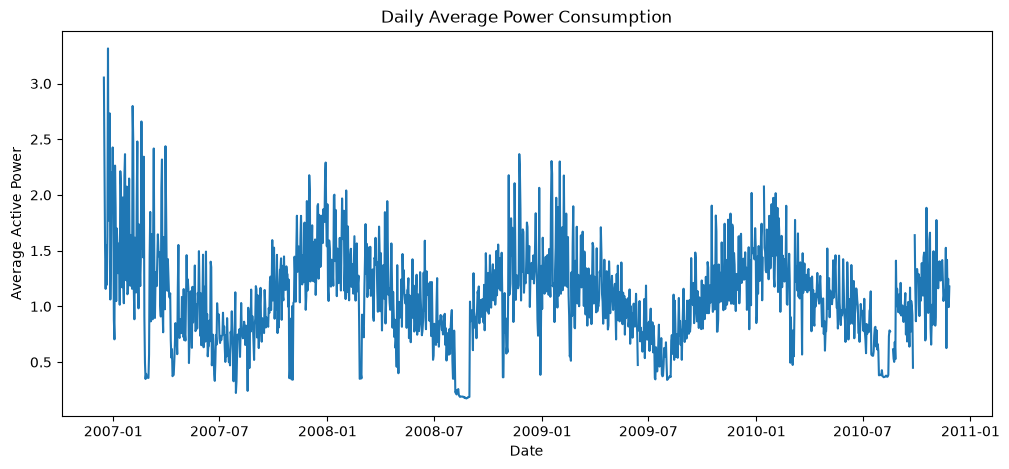

In [34]:
daily_consumption.plot(figsize=(12, 5), title="Daily Average Power Consumption")
plt.xlabel("Date")
plt.ylabel("Average Active Power")
plt.show()

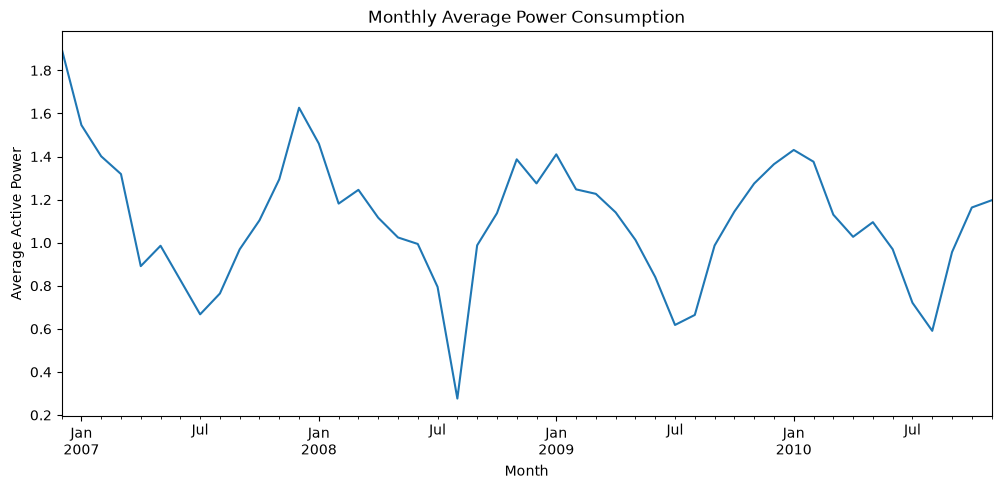

In [35]:
monthly_consumption.plot(figsize=(12, 5), title="Monthly Average Power Consumption")
plt.xlabel("Month")
plt.ylabel("Average Active Power")
plt.show()

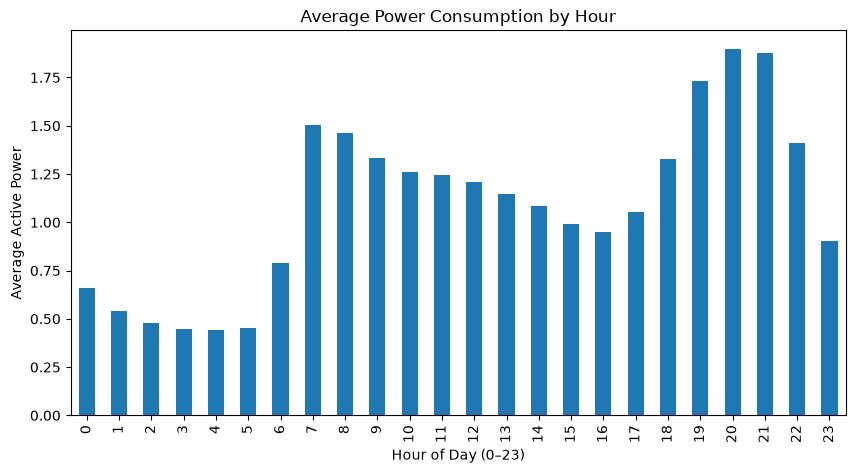

In [36]:
hourly_consumption.plot(kind="bar", figsize=(10, 5), title="Average Power Consumption by Hour")
plt.xlabel("Hour of Day (0–23)")
plt.ylabel("Average Active Power")
plt.show()

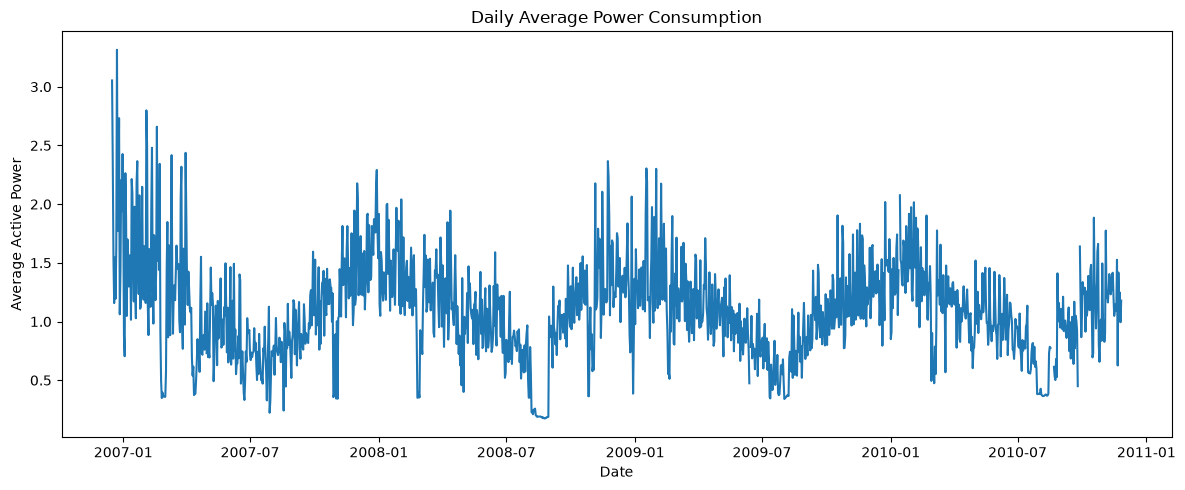

In [37]:
daily_consumption.plot(figsize=(12, 5), title="Daily Average Power Consumption")
plt.xlabel("Date")
plt.ylabel("Average Active Power")
plt.tight_layout()
plt.savefig("daily_consumption.png")
plt.show()

In [38]:
import os
os.path.exists("daily_consumption.png")

True

In [39]:
df.shape

(2075259, 11)

In [40]:
df.columns.tolist()

['Date',
 'Time',
 'Global_active_power',
 'Global_reactive_power',
 'Voltage',
 'Global_intensity',
 'Sub_metering_1',
 'Sub_metering_2',
 'Sub_metering_3',
 'datetime',
 'date']

In [41]:
df.isnull().sum()

Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
datetime                     0
date                         0
dtype: int64

In [42]:
missing_percentage = (df.isnull().sum() / len(df)) * 100
missing_percentage.round(2)

Date                     0.00
Time                     0.00
Global_active_power      1.25
Global_reactive_power    1.25
Voltage                  1.25
Global_intensity         1.25
Sub_metering_1           1.25
Sub_metering_2           1.25
Sub_metering_3           1.25
datetime                 0.00
date                     0.00
dtype: float64

In [43]:
df.duplicated().sum()

np.int64(0)

In [44]:
print("Start date:", df["datetime"].min())
print("End date:", df["datetime"].max())

Start date: 2006-12-16 17:24:00
End date: 2010-11-26 21:02:00


In [45]:
df.dtypes

Date                                str
Time                                str
Global_active_power             float64
Global_reactive_power           float64
Voltage                         float64
Global_intensity                float64
Sub_metering_1                  float64
Sub_metering_2                  float64
Sub_metering_3                  float64
datetime                 datetime64[us]
date                             object
dtype: object

In [46]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 2075259
Columns: 11


In [47]:
df["Global_active_power"].mean()

np.float64(1.0916150365006245)

In [48]:
df["Global_active_power"].max()

np.float64(11.122)

In [49]:
df["Global_active_power"].min()

np.float64(0.076)

In [50]:
df["Voltage"].mean()

np.float64(240.8398579745081)

In [51]:
df["Global_reactive_power"].mean()

np.float64(0.12371447630387258)

In [52]:
df["Sub_metering_1"].mean()

np.float64(1.1219233096502186)

In [53]:
df["Sub_metering_2"].mean()

np.float64(1.2985199679887571)

In [54]:
df["Sub_metering_3"].mean()

np.float64(6.45844735712055)

In [55]:
df.isnull().sum().sum()

np.int64(181853)

In [56]:
total_missing = df.isnull().sum().sum()
total_cells = df.shape[0] * df.shape[1]
print("Overall missing percentage:", round(total_missing / total_cells * 100, 2), "%")

Overall missing percentage: 0.8 %


In [57]:
df[numeric_columns].describe()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
count,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06
mean,1.091615e+00,1.237145e-01,2.408399e+02,4.627759e+00,1.121923e+00,1.298520e+00,6.458447e+00
std,1.057294e+00,1.127220e-01,3.239987e+00,4.444396e+00,6.153031e+00,5.822026e+00,8.437154e+00
min,7.600000e-02,0.000000e+00,2.232000e+02,2.000000e-01,0.000000e+00,0.000000e+00,0.000000e+00
25%,3.080000e-01,4.800000e-02,2.389900e+02,1.400000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,6.020000e-01,1.000000e-01,2.410100e+02,2.600000e+00,0.000000e+00,0.000000e+00,1.000000e+00
75%,1.528000e+00,1.940000e-01,2.428900e+02,6.400000e+00,0.000000e+00,1.000000e+00,1.700000e+01
max,1.112200e+01,1.390000e+00,2.541500e+02,4.840000e+01,8.800000e+01,8.000000e+01,3.100000e+01


In [58]:
df["Global_active_power"].isnull().sum()

np.int64(25979)

In [59]:
df["Voltage"].isnull().sum()

np.int64(25979)

In [60]:
df["Global_intensity"].isnull().sum()

np.int64(25979)

In [61]:
df["Sub_metering_1"].isnull().sum()

np.int64(25979)

In [62]:
df["Sub_metering_2"].isnull().sum()

np.int64(25979)

In [63]:
df["Sub_metering_3"].isnull().sum()

np.int64(25979)

In [64]:
df["Date"].isnull().sum()

np.int64(0)

In [65]:
df["Time"].isnull().sum()

np.int64(0)

In [66]:
df["datetime"].isnull().sum()

np.int64(0)

In [67]:
df["date"].isnull().sum()

np.int64(0)

In [68]:
len(df)

2075259

In [69]:
df["date"].nunique()

1442

In [70]:
df["datetime"].dt.hour.nunique()

24

In [71]:
df["datetime"].dt.dayofweek.nunique()

7

In [72]:
df["datetime"].head()

0   2006-12-16 17:24:00
1   2006-12-16 17:25:00
2   2006-12-16 17:26:00
3   2006-12-16 17:27:00
4   2006-12-16 17:28:00
Name: datetime, dtype: datetime64[us]

In [73]:
df["month"] = df["datetime"].dt.month
df["month"].head()

0    12
1    12
2    12
3    12
4    12
Name: month, dtype: int32

In [74]:
df["year"] = df["datetime"].dt.year
df["year"].head()

0    2006
1    2006
2    2006
3    2006
4    2006
Name: year, dtype: int32

In [75]:
df["day_of_week"] = df["datetime"].dt.day_name()
df["day_of_week"].head()

0    Saturday
1    Saturday
2    Saturday
3    Saturday
4    Saturday
Name: day_of_week, dtype: str

In [76]:
df["hour"] = df["datetime"].dt.hour
df["hour"].head()

0    17
1    17
2    17
3    17
4    17
Name: hour, dtype: int32

In [77]:
df[["datetime", "month", "year", "day_of_week", "hour"]].head()

,datetime,month,year,day_of_week,hour
0,2006-12-16 17:24:00,12,2006,Saturday,17
1,2006-12-16 17:25:00,12,2006,Saturday,17
2,2006-12-16 17:26:00,12,2006,Saturday,17
3,2006-12-16 17:27:00,12,2006,Saturday,17
4,2006-12-16 17:28:00,12,2006,Saturday,17


In [78]:
monthly_avg = df.groupby("month")["Global_active_power"].mean()
monthly_avg

month
1     1.462226
2     1.300431
3     1.231343
4     1.047146
5     1.029571
6     0.909148
7     0.700359
8     0.572812
9     0.975653
10    1.137141
11    1.291532
12    1.489729
Name: Global_active_power, dtype: float64

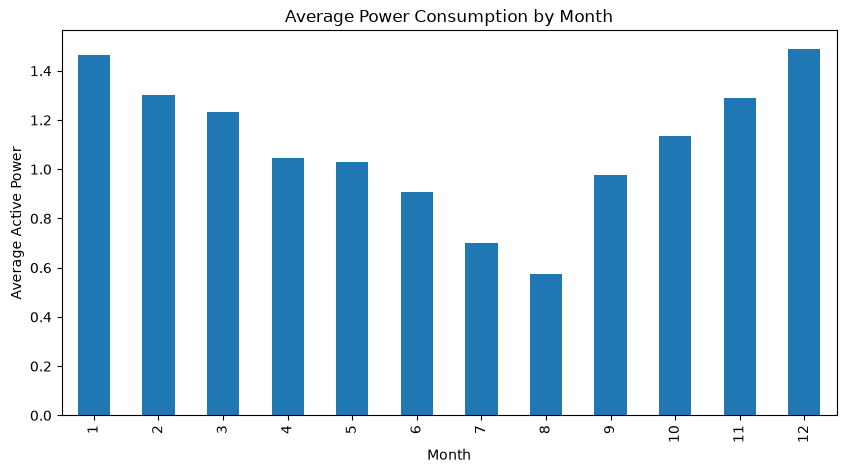

In [79]:
monthly_avg.plot(kind="bar", figsize=(10, 5), title="Average Power Consumption by Month")
plt.xlabel("Month")
plt.ylabel("Average Active Power")
plt.show()

In [80]:
weekday_avg = df.groupby("day_of_week")["Global_active_power"].mean()
weekday_avg

day_of_week
Friday       1.043394
Monday       0.999546
Saturday     1.248335
Sunday       1.220188
Thursday     0.981809
Tuesday      1.069796
Wednesday    1.082588
Name: Global_active_power, dtype: float64

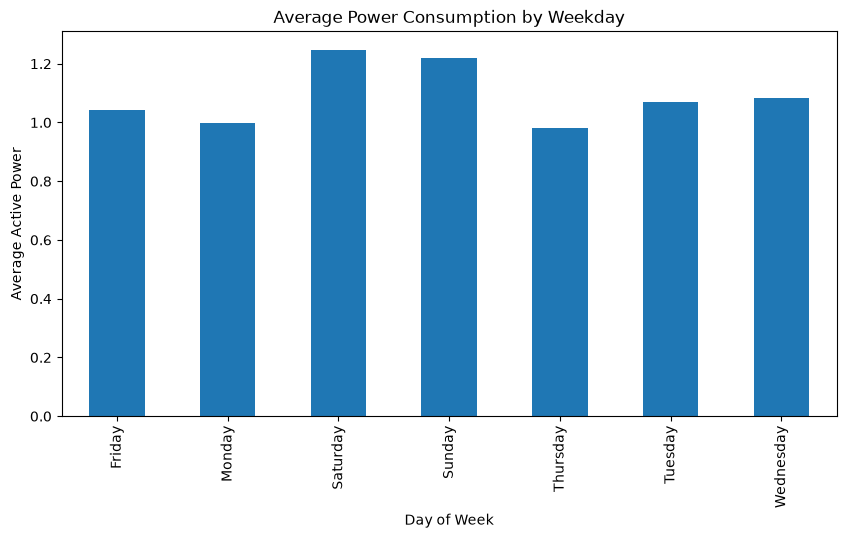

In [81]:
weekday_avg.plot(kind="bar", figsize=(10, 5), title="Average Power Consumption by Weekday")
plt.xlabel("Day of Week")
plt.ylabel("Average Active Power")
plt.show()

In [82]:
hourly_avg = df.groupby("hour")["Global_active_power"].mean()
hourly_avg

hour
0     0.659434
1     0.539325
2     0.480621
3     0.444866
4     0.443847
5     0.453674
6     0.791600
7     1.502246
8     1.461016
9     1.331645
10    1.260627
11    1.245822
12    1.207075
13    1.144532
14    1.082839
15    0.990760
16    0.948905
17    1.055109
18    1.326451
19    1.733335
20    1.899064
21    1.877697
22    1.412615
23    0.902142
Name: Global_active_power, dtype: float64

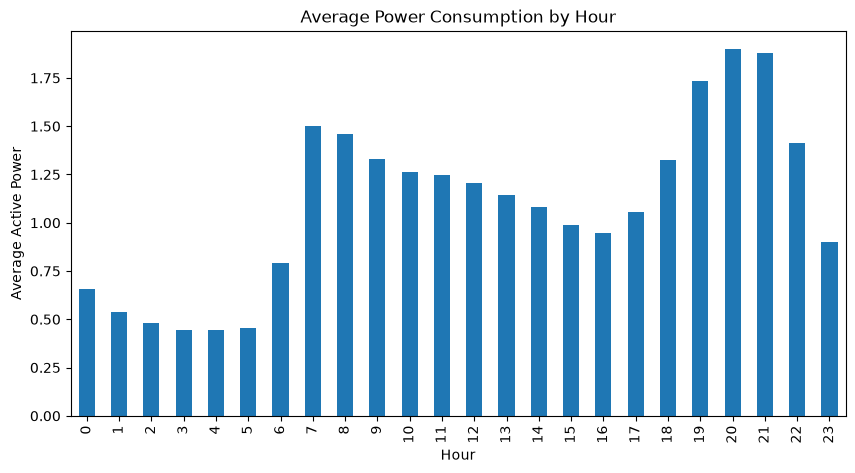

In [83]:
hourly_avg.plot(kind="bar", figsize=(10, 5), title="Average Power Consumption by Hour")
plt.xlabel("Hour")
plt.ylabel("Average Active Power")
plt.show()

In [84]:
hourly_avg.sort_values(ascending=False).head(5)

hour
20    1.899064
21    1.877697
19    1.733335
7     1.502246
8     1.461016
Name: Global_active_power, dtype: float64

In [85]:
hourly_avg.sort_values(ascending=True).head(5)

hour
4    0.443847
3    0.444866
5    0.453674
2    0.480621
1    0.539325
Name: Global_active_power, dtype: float64

In [86]:
weekday_avg.sort_values(ascending=False)

day_of_week
Saturday     1.248335
Sunday       1.220188
Wednesday    1.082588
Tuesday      1.069796
Friday       1.043394
Monday       0.999546
Thursday     0.981809
Name: Global_active_power, dtype: float64

In [87]:
monthly_avg.sort_values(ascending=False)

month
12    1.489729
1     1.462226
2     1.300431
11    1.291532
3     1.231343
10    1.137141
4     1.047146
5     1.029571
9     0.975653
6     0.909148
7     0.700359
8     0.572812
Name: Global_active_power, dtype: float64

In [88]:
hourly_avg.describe()


count    24.000000
mean      1.091469
std       0.444233
min       0.443847
25%       0.758558
50%       1.113686
75%       1.351888
max       1.899064
Name: Global_active_power, dtype: float64

In [89]:
weekday_avg.describe()

count    7.000000
mean     1.092237
std      0.103687
min      0.981809
25%      1.021470
50%      1.069796
75%      1.151388
max      1.248335
Name: Global_active_power, dtype: float64

In [90]:
df.shape

(2075259, 15)

In [91]:
df.columns.tolist()

['Date',
 'Time',
 'Global_active_power',
 'Global_reactive_power',
 'Voltage',
 'Global_intensity',
 'Sub_metering_1',
 'Sub_metering_2',
 'Sub_metering_3',
 'datetime',
 'date',
 'month',
 'year',
 'day_of_week',
 'hour']